# Exploratory Data Analysis and Time-Series Visualization of Gold Prices (2000-2026)
**Course:** EDAV (22ADC31N) | **Dataset:** `finalgolddata.csv` (daily Open, High, Low, Close, Volume)

Same workflow as the youth-hostel report: load -> audit -> clean -> EDA -> analytics -> findings.
Note: this dataset has no place names or coordinates, so the geospatial section of the sample
report is replaced with time-series analytics (trend, returns, volatility, drawdowns, seasonality).

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

OUT = 'outputs'; FIG = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)

def savefig(name):
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')

print('pandas', pd.__version__)

pandas 2.2.3


## 2. Load the data
**Concept:** load the raw file unchanged and keep a copy so every cleaning step is traceable.

In [2]:
CANDIDATES = ['finalgolddata.csv', '/content/finalgolddata.csv', '/mnt/user-data/uploads/finalgolddata.csv']
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:                      # Google Colab fallback: upload the file
    try:
        from google.colab import files
        path = list(files.upload())[0]
    except ImportError:
        raise FileNotFoundError('Place finalgolddata.csv in the same folder as this notebook.')

raw = pd.read_csv(path)
print('Loaded from:', path)
print('Shape (rows, columns):', raw.shape)
raw.head(8)

Saving finalgolddata.csv to finalgolddata.csv
Loaded from: finalgolddata.csv
Shape (rows, columns): (6399, 6)


,Date,Open,High,Low,Close,Volume
0,30-08-00,273.899994,273.899994,273.899994,273.899994,0
1,31-08-00,274.799988,278.299988,274.799988,278.299988,0
2,01-09-00,277.000000,277.000000,277.000000,277.000000,0
3,05-09-00,275.799988,275.799988,275.799988,275.799988,2
4,06-09-00,274.200012,274.200012,274.200012,274.200012,0
5,07-09-00,274.000000,274.000000,274.000000,274.000000,125
6,08-09-00,273.299988,273.299988,273.299988,273.299988,0
7,11-09-00,273.100006,273.100006,273.100006,273.100006,0


## 3. Data understanding
One row = one trading day. Columns: `Date` (dd-mm-yy text), `Open`, `High`, `Low`, `Close` (price),
`Volume` (trade volume, integer).

In [3]:
raw.info()
print('\nMissing values per column:'); print(raw.isna().sum())
print('\nDuplicate rows:', raw.duplicated().sum())
print('Duplicate dates:', raw['Date'].duplicated().sum())
raw.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6399 entries, 0 to 6398
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    6399 non-null   object 
 1   Open    6399 non-null   float64
 2   High    6399 non-null   float64
 3   Low     6399 non-null   float64
 4   Close   6399 non-null   float64
 5   Volume  6399 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 300.1+ KB

Missing values per column:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate rows: 0
Duplicate dates: 0


,count,mean,std,min,25%,50%,75%,max
Open,6399.0,1274.892437,782.868133,255.000000,651.000000,1251.599976,1694.700012,5415.700195
High,6399.0,1281.728724,788.800733,256.100006,653.649994,1256.199951,1706.099976,5586.200195
Low,6399.0,1267.908032,777.090788,255.000000,649.149994,1244.800049,1683.250000,5334.899902
Close,6399.0,1274.961009,783.122438,255.100006,651.699982,1251.099976,1695.649964,5377.299805
Volume,6399.0,4282.543522,24051.637361,0.000000,23.000000,117.000000,450.500000,386334.000000


## 4. Cleaning and feature engineering
### 4.1 Parse dates (the year is 2-digit, `dd-mm-yy`)

In [4]:
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%y')
df = df.sort_values('Date').reset_index(drop=True)
print('Range:', df.Date.min().date(), '->', df.Date.max().date())
print('Sorted & unique dates:', df.Date.is_monotonic_increasing, not df.Date.duplicated().any())

Range: 2000-08-30 -> 2026-03-03
Sorted & unique dates: True True


### 4.2 Data-quality audit (the most important step)
Checks: (1) calendar gaps, (2) OHLC logic (`High` >= all, `Low` <= all), (3) zero-volume days,
(4) extreme one-day moves.

In [5]:
# (1) gaps between consecutive trading days
gap = df.Date.diff().dt.days
print('Largest gap between rows (days):', int(gap.max()), '| gaps > 5 days:', int((gap > 5).sum()))

# (2) OHLC logic
hi_bad = df.High < df[['Open', 'Close', 'Low']].max(axis=1)
lo_bad = df.Low  > df[['Open', 'Close', 'High']].min(axis=1)
bad = hi_bad | lo_bad
print(f'OHLC inconsistent rows: {bad.sum()} ({bad.mean():.1%})')
viol = (df[['Open', 'Close', 'Low']].max(axis=1) - df.High).clip(lower=0) + \
       (df.Low - df[['Open', 'Close', 'High']].min(axis=1)).clip(lower=0)
print('Size of violation (price units) among bad rows:'); print(viol[bad].describe().round(3))

# (3) zero volume
print(f'\nZero-volume days: {(df.Volume == 0).sum()} ({(df.Volume == 0).mean():.1%})')
print(df.assign(year=df.Date.dt.year).groupby('year').Volume.apply(lambda s: (s == 0).mean()).round(2).to_string())

# (4) flat days (Open = High = Low = Close) - typical of illiquid early data
flat = (df.Open == df.High) & (df.High == df.Low) & (df.Low == df.Close)
print('\nFlat OHLC days:', flat.sum())

Largest gap between rows (days): 5 | gaps > 5 days: 0
OHLC inconsistent rows: 441 (6.9%)
Size of violation (price units) among bad rows:
count    441.000
mean       3.209
std        4.887
min        0.100
25%        0.600
50%        1.700
75%        3.700
max       48.100
dtype: float64

Zero-volume days: 418 (6.5%)
year
2000    0.45
2001    0.42
2002    0.33
2003    0.10
2004    0.08
2005    0.19
2006    0.13
2007    0.11
2008    0.00
2009    0.00
2010    0.00
2011    0.00
2012    0.00
2013    0.00
2014    0.01
2015    0.00
2016    0.00
2017    0.00
2018    0.07
2019    0.04
2020    0.00
2021    0.00
2022    0.00
2023    0.00
2024    0.00
2025    0.02
2026    0.00

Flat OHLC days: 812


**Treatment rule:** never silently drop. Fix OHLC logic by widening High/Low to cover Open/Close
(flag the rows), keep zero-volume days but flag them, and treat Volume as unreliable for early years.

In [6]:
df['ohlc_fixed'] = bad
df['High'] = df[['Open', 'High', 'Low', 'Close']].max(axis=1)
df['Low']  = df[['Open', 'High', 'Low', 'Close']].min(axis=1)
df['zero_volume'] = df.Volume == 0

### 4.3 Feature engineering

In [7]:
df['ret']      = df.Close.pct_change()                     # simple daily return
df['logret']   = np.log(df.Close).diff()                   # log return
df['range_pct'] = (df.High - df.Low) / df.Close * 100      # intraday range %
df['year']     = df.Date.dt.year
df['month']    = df.Date.dt.month
df['dow']      = df.Date.dt.dayofweek
df['MA50']     = df.Close.rolling(50).mean()
df['MA200']    = df.Close.rolling(200).mean()
df['vol30']    = df.logret.rolling(30).std() * np.sqrt(252) * 100    # annualised volatility %
df['vol252']   = df.logret.rolling(252).std() * np.sqrt(252) * 100
df['peak']     = df.Close.cummax()
df['drawdown'] = (df.Close / df['peak'] - 1) * 100
df['golden_cross'] = df.MA50 > df.MA200
df = df.set_index('Date')
df.tail()

,Open,High,Low,Close,Volume,ohlc_fixed,zero_volume,ret,logret,range_pct,year,month,dow,MA50,MA200,vol30,vol252,peak,drawdown,golden_cross
Date,,,,,,,,,,,,,,,,,,,,
2026-02-25,5166.000000,5206.399902,5166.000000,5206.399902,1772,False,False,0.009814,0.009766,0.775966,2026,2,2,4726.749990,3912.988990,48.642291,26.140303,5318.399902,-2.105897,True
2026-02-26,5177.200195,5199.200195,5143.899902,5176.500000,1520,False,False,-0.005743,-0.005759,1.068295,2026,2,3,4744.277988,3922.771490,48.680195,26.152047,5318.399902,-2.668094,True
2026-02-27,5186.700195,5280.000000,5176.700195,5230.500000,354,False,False,0.010432,0.010378,1.974951,2026,2,4,4762.753984,3932.722490,48.701623,26.127378,5318.399902,-1.652751,True
2026-03-02,5346.600098,5405.000000,5266.299805,5294.399902,354,False,False,0.012217,0.012143,2.619753,2026,3,0,4782.551982,3943.287490,48.718451,26.078712,5318.399902,-0.451264,True
2026-03-03,5335.700195,5394.200195,5334.899902,5377.299805,21189,False,False,0.015658,0.015537,1.102789,2026,3,1,4803.147979,3954.070489,48.711084,26.061185,5377.299805,0.000000,True


## 5. Exploratory Data Analysis
### 5.1 Summary statistics

In [8]:
stats = pd.DataFrame({
    'Start price': [df.Close.iloc[0]], 'Latest price': [df.Close.iloc[-1]],
    'Min': [df.Close.min()], 'Max': [df.Close.max()],
    'Mean': [df.Close.mean()], 'Median': [df.Close.median()], 'Std dev': [df.Close.std()],
    'Trading days': [len(df)],
}).T.rename(columns={0: 'Close'}).round(2)
years = (df.index[-1] - df.index[0]).days / 365.25
cagr = (df.Close.iloc[-1] / df.Close.iloc[0]) ** (1 / years) - 1
print(f'Period: {years:.1f} years | Total return: {df.Close.iloc[-1]/df.Close.iloc[0]-1:.0%} | CAGR: {cagr:.2%}')
stats

Period: 25.5 years | Total return: 1863% | CAGR: 12.38%


,Close
Start price,273.90
Latest price,5377.30
Min,255.10
Max,5377.30
Mean,1274.96
Median,1251.10
Std dev,783.12
Trading days,6399.00


### 5.2 Price trend with moving averages
**Concept:** the 50-day and 200-day moving averages smooth noise; crossings signal trend changes.

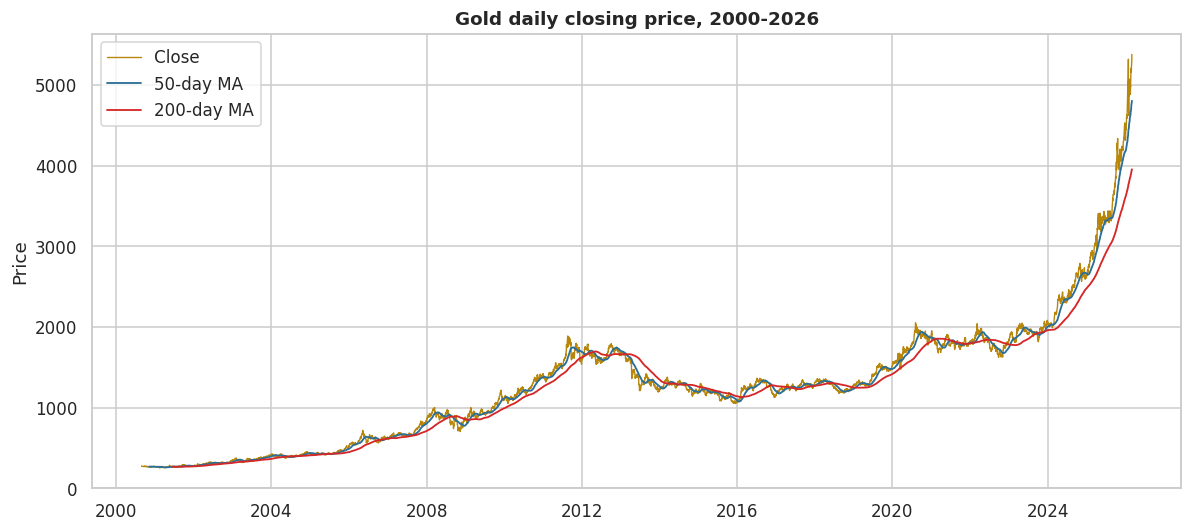

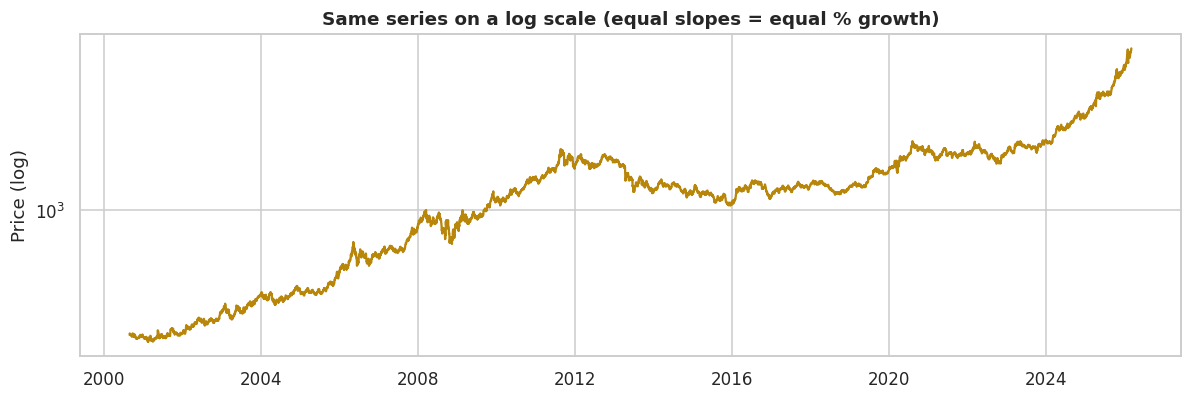

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df.index, df.Close, lw=.9, color='#b8860b', label='Close')
ax.plot(df.index, df.MA50, lw=1.2, color='#2a6f97', label='50-day MA')
ax.plot(df.index, df.MA200, lw=1.2, color='#d62728', label='200-day MA')
ax.set_title('Gold daily closing price, 2000-2026', fontweight='bold'); ax.set_ylabel('Price'); ax.legend()
plt.tight_layout(); savefig('01_price_trend'); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.semilogy(df.index, df.Close, color='#b8860b')
ax.set_title('Same series on a log scale (equal slopes = equal % growth)', fontweight='bold'); ax.set_ylabel('Price (log)')
plt.tight_layout(); savefig('02_price_log'); plt.show()

### 5.3 Year-by-year performance

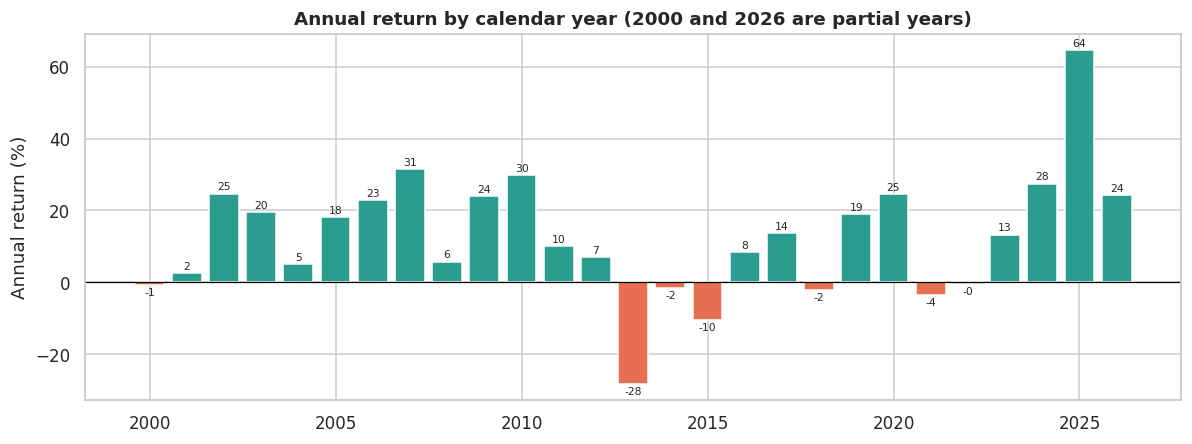

Positive years: 20 of 27


,open,close,low,high,days,return_%
year,,,,,,
2000,273.899994,272.000000,263.899994,278.399994,84,-0.7
2001,268.399994,278.700012,255.000000,294.000000,247,2.5
2002,278.899994,347.600006,278.100006,350.500000,250,24.7
2003,346.100006,415.700012,319.299988,417.200012,250,19.6
2004,415.700012,437.500000,374.799988,456.500000,249,5.2
2005,431.000000,517.099976,410.100006,538.500000,248,18.2
2006,518.599976,635.200012,518.599976,723.000000,250,22.8
2007,635.200012,834.900024,604.900024,843.200012,252,31.4
2008,848.700012,883.599976,681.000000,1014.599976,253,5.8


In [10]:
yearly = df.groupby('year').agg(open=('Open', 'first'), close=('Close', 'last'),
                                low=('Low', 'min'), high=('High', 'max'), days=('Close', 'count'))
yearly['return_%'] = (yearly.close / yearly.close.shift(1) - 1) * 100
yearly.loc[yearly.index[0], 'return_%'] = (yearly.close.iloc[0] / yearly.open.iloc[0] - 1) * 100  # partial first year
yearly['return_%'] = yearly['return_%'].round(1)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(yearly.index, yearly['return_%'], color=np.where(yearly['return_%'] > 0, '#2a9d8f', '#e76f51'))
for x, v in zip(yearly.index, yearly['return_%']):
    ax.text(x, v + (1 if v > 0 else -3), f'{v:.0f}', ha='center', fontsize=7)
ax.axhline(0, color='black', lw=.8); ax.set_ylabel('Annual return (%)')
ax.set_title('Annual return by calendar year (2000 and 2026 are partial years)', fontweight='bold')
plt.tight_layout(); savefig('03_annual_returns'); plt.show()
print('Positive years:', (yearly['return_%'] > 0).sum(), 'of', len(yearly))
yearly

### 5.4 Distribution of daily returns
**Concept:** financial returns are rarely normal - they have fat tails (excess kurtosis).

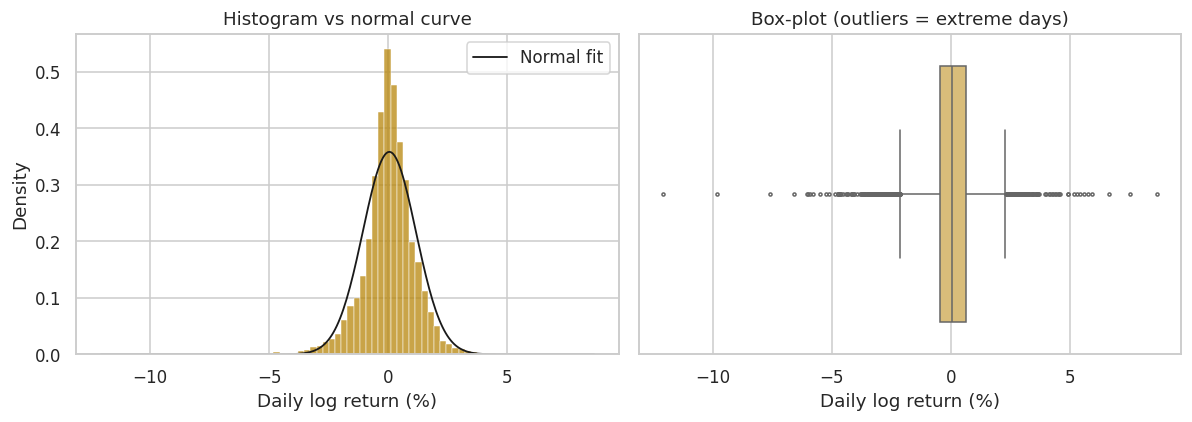

Mean daily return: 0.0465% | Std: 1.1142%
Skewness: -0.47 | Excess kurtosis: 7.02  (normal = 0)
Days beyond +/-3 std: 84  (normal expects ~17)

Largest daily moves:
                  Close  log_return_pct
Date                                   
2026-01-30  4713.899902          -12.07
2013-04-15  1360.599976           -9.82
2008-09-17   846.599976            8.64
2006-06-13   562.500000           -7.58
2009-03-19   958.299988            7.54
2001-09-14   290.200012            6.62
2013-06-20  1285.900024           -6.60
2011-09-23  1637.500000           -6.03


In [11]:
r = df.logret.dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(r * 100, bins=80, stat='density', color='#b8860b', ax=axes[0])
xs = np.linspace(r.min() * 100, r.max() * 100, 300)
axes[0].plot(xs, np.exp(-0.5 * ((xs - r.mean()*100) / (r.std()*100)) ** 2) / (r.std()*100 * np.sqrt(2*np.pi)),
             color='k', lw=1.2, label='Normal fit')
axes[0].set_xlabel('Daily log return (%)'); axes[0].set_title('Histogram vs normal curve'); axes[0].legend()
sns.boxplot(x=r * 100, color='#e9c46a', ax=axes[1], fliersize=2)
axes[1].set_xlabel('Daily log return (%)'); axes[1].set_title('Box-plot (outliers = extreme days)')
plt.tight_layout(); savefig('04_return_distribution'); plt.show()

print(f'Mean daily return: {r.mean():.4%} | Std: {r.std():.4%}')
print(f'Skewness: {r.skew():.2f} | Excess kurtosis: {r.kurt():.2f}  (normal = 0)')
print(f'Days beyond +/-3 std: {(abs(r - r.mean()) > 3 * r.std()).sum()}  (normal expects ~{len(r)*0.0027:.0f})')
print('\nLargest daily moves:')
print((df.logret.abs().nlargest(8).index.to_series().to_frame('Date')
       .assign(Close=df.Close, log_return_pct=(df.logret * 100).round(2))
       .drop(columns='Date')).to_string())

### 5.5 Volatility over time

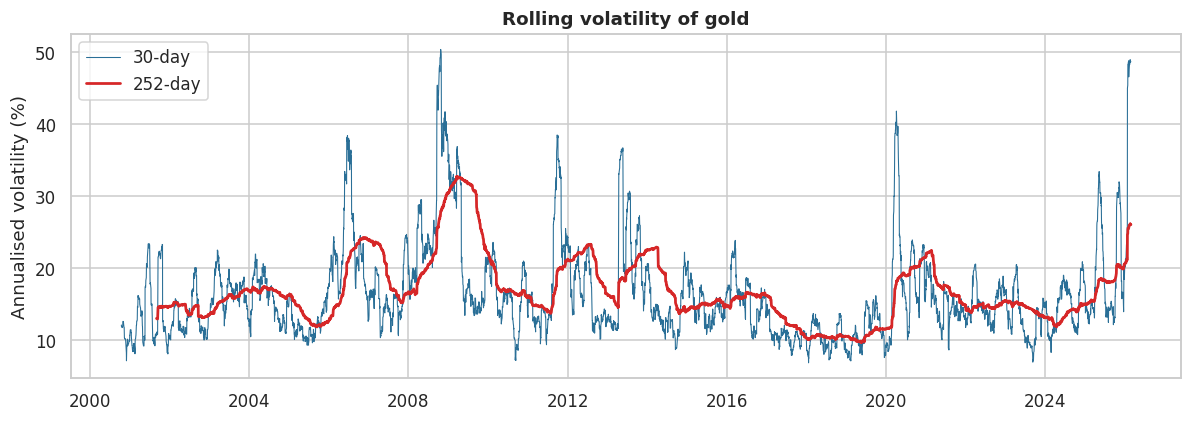

Highest-volatility years:
year
2026    42.6
2008    30.5
2006    24.0
2013    22.5
2009    22.1


In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df.index, df.vol30, lw=.7, color='#2a6f97', label='30-day')
ax.plot(df.index, df.vol252, lw=1.8, color='#d62728', label='252-day')
ax.set_ylabel('Annualised volatility (%)'); ax.legend()
ax.set_title('Rolling volatility of gold', fontweight='bold')
plt.tight_layout(); savefig('05_volatility'); plt.show()
print('Highest-volatility years:'); print(df.groupby('year').logret.std().mul(np.sqrt(252) * 100).round(1).nlargest(5).to_string())

### 5.6 Drawdowns - how far below the previous peak?

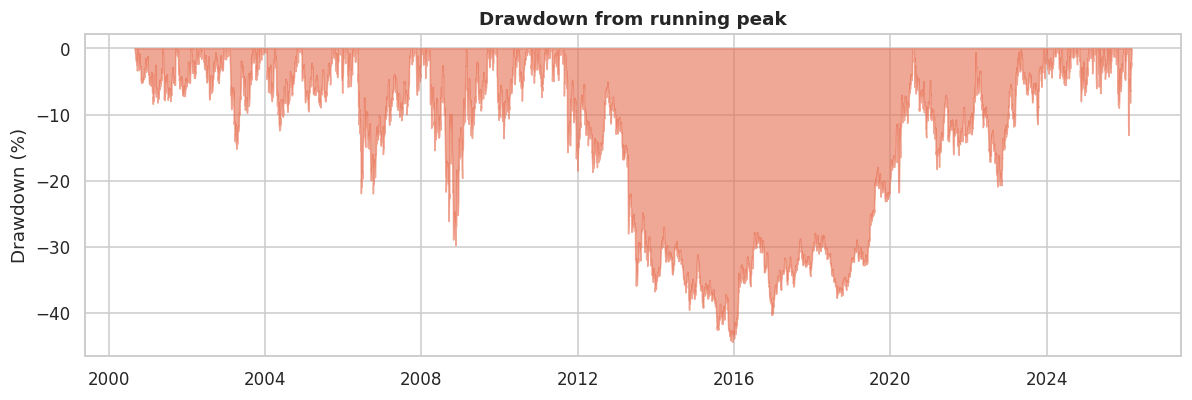

Max drawdown: -44.4% | peak 2011-08-22 -> trough 2015-12-17
Recovered on: 2020-07-23


In [13]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(df.index, df.drawdown, 0, color='#e76f51', alpha=.6)
ax.set_ylabel('Drawdown (%)'); ax.set_title('Drawdown from running peak', fontweight='bold')
plt.tight_layout(); savefig('06_drawdown'); plt.show()

trough = df.drawdown.idxmin()
peak = df.loc[:trough, 'Close'].idxmax()
rec = df.loc[trough:][df.loc[trough:, 'Close'] >= df.loc[peak, 'Close']]
print(f'Max drawdown: {df.drawdown.min():.1f}% | peak {peak.date()} -> trough {trough.date()}')
print('Recovered on:', rec.index[0].date() if len(rec) else 'not yet recovered')

### 5.7 Seasonality - month and weekday effects

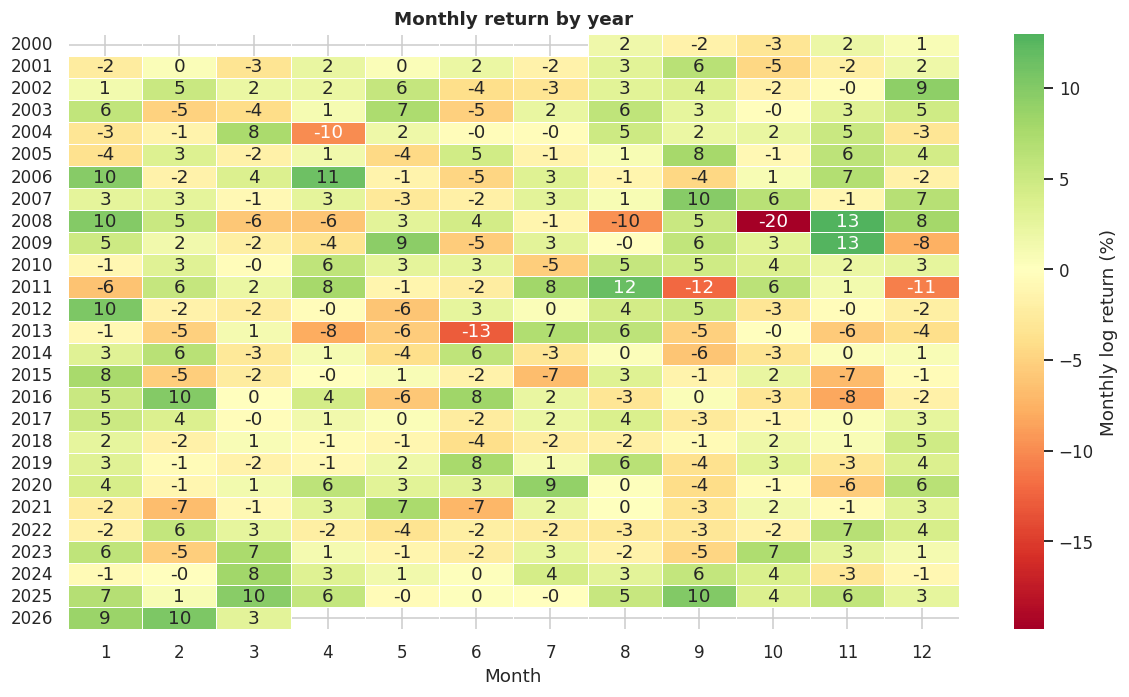

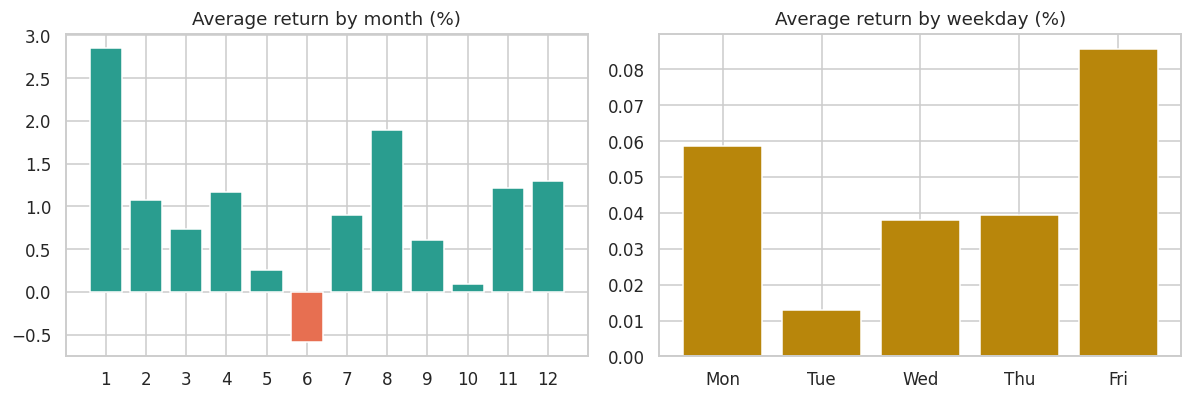

Month 1: mean 0.141%/day, t-stat 2.73
Month 8: mean 0.089%/day, t-stat 2.11


In [14]:
month_ret = df.groupby(['year', 'month']).logret.sum().unstack() * 100
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(month_ret, annot=True, fmt='.0f', cmap='RdYlGn', center=0, linewidths=.4,
            cbar_kws={'label': 'Monthly log return (%)'}, ax=ax)
ax.set_title('Monthly return by year', fontweight='bold'); ax.set_xlabel('Month'); ax.set_ylabel('')
plt.tight_layout(); savefig('07_month_year_heatmap'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
m = month_ret.mean(); axes[0].bar(m.index, m.values, color=np.where(m.values > 0, '#2a9d8f', '#e76f51'))
axes[0].set_title('Average return by month (%)'); axes[0].set_xticks(range(1, 13))
d = df.groupby('dow').logret.mean() * 100
axes[1].bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri'][:len(d)], d.values, color='#b8860b')
axes[1].set_title('Average return by weekday (%)')
plt.tight_layout(); savefig('08_seasonality'); plt.show()

# simple significance check: is the best month really different from zero?
from math import sqrt
for mm, g in df.groupby('month').logret:
    t = g.mean() / (g.std() / sqrt(len(g)))
    if abs(t) > 2: print(f'Month {mm}: mean {g.mean()*100:.3f}%/day, t-stat {t:.2f}')

### 5.8 Volume and its relation to price
Volume is zero on many early days, so interpret it only after the market became liquid.

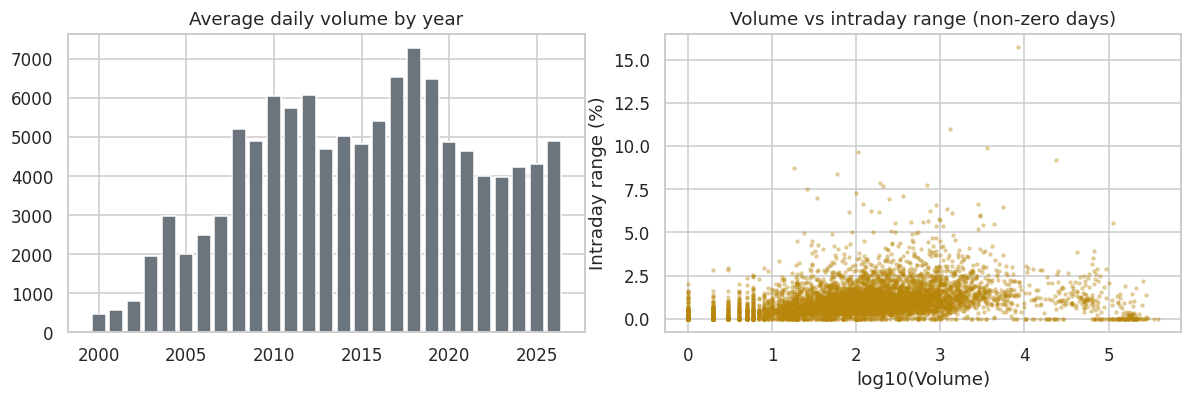

Correlation (log volume vs |return|): 0.076


In [15]:
vol_year = df.groupby('year').Volume.mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(vol_year.index, vol_year.values, color='#6c757d'); axes[0].set_title('Average daily volume by year')
active = df[df.Volume > 0]
axes[1].scatter(np.log10(active.Volume), active.range_pct, s=4, alpha=.3, color='#b8860b')
axes[1].set_xlabel('log10(Volume)'); axes[1].set_ylabel('Intraday range (%)')
axes[1].set_title('Volume vs intraday range (non-zero days)')
plt.tight_layout(); savefig('09_volume'); plt.show()
print('Correlation (log volume vs |return|):',
      round(np.log10(active.Volume).corr(active.logret.abs()), 3))

### 5.9 Correlation heat-map

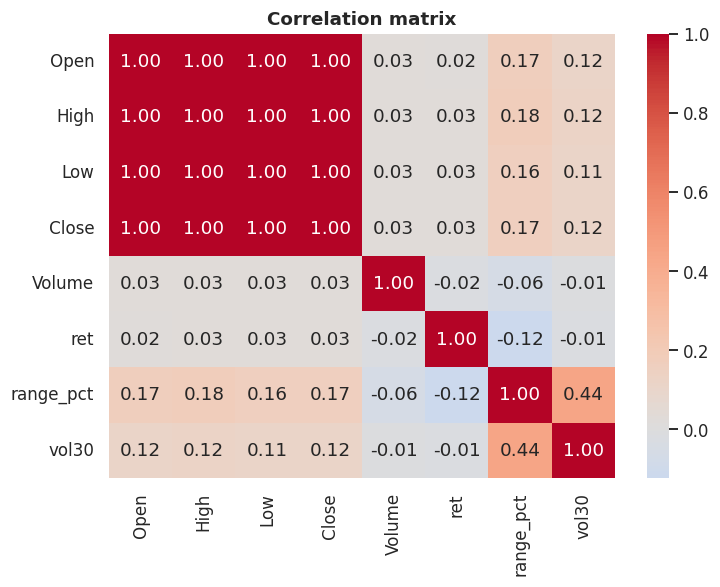

Note: Open/High/Low/Close are ~1.0 correlated by construction; use returns for meaningful relationships.


In [16]:
cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'ret', 'range_pct', 'vol30']
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation matrix', fontweight='bold'); plt.tight_layout(); savefig('10_correlation'); plt.show()
print('Note: Open/High/Low/Close are ~1.0 correlated by construction; use returns for meaningful relationships.')

## 6. Analytics
### 6.1 Market regimes with K-Means (unsupervised learning)
Group each year into regimes using annual return and annualised volatility.

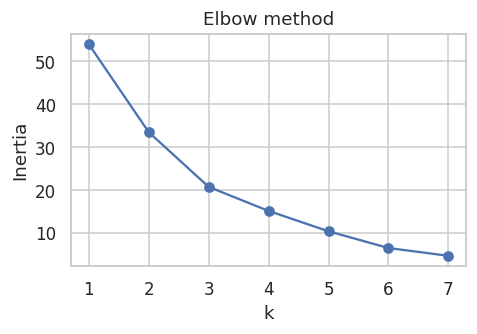

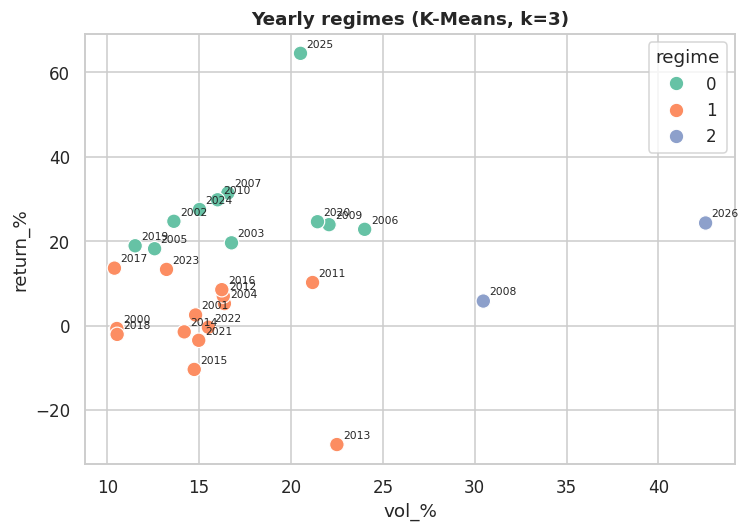

,years,avg_return,avg_vol
regime,,,
0,11,27.8,17.3
1,14,1.0,15.1
2,2,15.0,36.5


In [17]:
ann = pd.DataFrame({'return_%': yearly['return_%'],
                    'vol_%': df.groupby('year').logret.std() * np.sqrt(252) * 100}).dropna()
Xs = StandardScaler().fit_transform(ann)
inertia = [KMeans(k, n_init=10, random_state=42).fit(Xs).inertia_ for k in range(1, 8)]
fig, ax = plt.subplots(figsize=(4.5, 3.2)); ax.plot(range(1, 8), inertia, marker='o')
ax.set_xlabel('k'); ax.set_ylabel('Inertia'); ax.set_title('Elbow method'); plt.tight_layout(); plt.show()

K = 3
ann['regime'] = KMeans(K, n_init=10, random_state=42).fit_predict(Xs)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=ann, x='vol_%', y='return_%', hue='regime', palette='Set2', s=90, ax=ax)
for y, row in ann.iterrows(): ax.annotate(str(y), (row['vol_%'], row['return_%']), xytext=(4, 4), textcoords='offset points', fontsize=7)
ax.set_title(f'Yearly regimes (K-Means, k={K})', fontweight='bold'); plt.tight_layout(); savefig('11_regimes'); plt.show()
ann.groupby('regime').agg(years=('return_%', 'size'), avg_return=('return_%', 'mean'), avg_vol=('vol_%', 'mean')).round(1)

### 6.2 Trend signal: golden cross / death cross

In [18]:
cross = df.golden_cross.astype(int).diff().dropna()
events = cross[cross != 0]
print('Golden crosses (MA50 above MA200):', (events == 1).sum(), '| Death crosses:', (events == -1).sum())
up = df[df.golden_cross & df.MA200.notna()].logret.mean()
dn = df[~df.golden_cross & df.MA200.notna()].logret.mean()
print(f'Avg daily return while MA50 > MA200: {up:.4%} vs MA50 < MA200: {dn:.4%}')

Golden crosses (MA50 above MA200): 17 | Death crosses: 16
Avg daily return while MA50 > MA200: 0.0554% vs MA50 < MA200: 0.0287%


### 6.3 Baseline next-day price forecast
Strict chronological split (no shuffling). Compare a naive baseline, a moving average and Ridge on lagged returns.

In [19]:
d = df[['Close', 'logret']].copy()
for L in range(1, 6): d[f'lag{L}'] = d.logret.shift(L)
d['target'] = d.logret.shift(-1)
d = d.dropna()
split = int(len(d) * 0.8)
tr, te = d.iloc[:split], d.iloc[split:]
feat = [f'lag{L}' for L in range(1, 6)]

model = Ridge(alpha=1.0).fit(tr[feat], tr.target)
pred_ret = model.predict(te[feat])

actual = te.Close * np.exp(te.target)               # next-day close
naive  = te.Close                                    # tomorrow = today
ma5    = df.Close.rolling(5).mean().reindex(te.index)
ridge  = te.Close * np.exp(pred_ret)

def metrics(y, p):
    e = y - p; return pd.Series({'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()),
                                 'MAPE_%': (e.abs() / y).mean() * 100})
res = pd.DataFrame({'Naive (yesterday)': metrics(actual, naive), '5-day MA': metrics(actual, ma5),
                    'Ridge on lagged returns': metrics(actual, ridge)}).T.round(3)
print(f'Train: {tr.index[0].date()} -> {tr.index[-1].date()} | Test: {te.index[0].date()} -> {te.index[-1].date()}')
res

Train: 2000-09-08 -> 2021-01-28 | Test: 2021-01-29 -> 2026-03-02


,MAE,RMSE,MAPE_%
Naive (yesterday),19.980,35.762,0.774
5-day MA,30.112,48.315,1.162
Ridge on lagged returns,19.882,35.662,0.771


Interpretation: if the naive forecast is as good as or better than the model, daily gold returns carry
almost no linear memory - which is itself a finding (consistent with an efficient market).

## 7. Key findings (fill in from your own outputs)
1. Overall growth, CAGR and latest price (section 5.1).
2. Number of positive years and the strongest/weakest years (section 5.3).
3. Fat tails: skewness, kurtosis and extreme days (section 5.4).
4. Highest-volatility periods and maximum drawdown with recovery date (sections 5.5, 5.6).
5. Seasonality - only report effects that pass the t-stat check (section 5.7).
6. Data caveats: OHLC fixes, zero-volume days, 2-digit year format, partial years 2000 and 2026.

## 8. Limitations
* No metadata: currency/unit, exchange and source are not in the file - cite the publisher in the report.
* Volume is unreliable (many zeros, especially early on).
* Past price behaviour is not investment advice; the forecast is a teaching baseline.

## 9. Future scope
* Add USD index, inflation, interest rates, crude oil to explain price moves.
* Try ARIMA/GARCH/LSTM models; add a Streamlit dashboard.